# Setup

In [1]:
lapply(c('viridis', 'ggthemes', 'skimr'),
       function(pkg_name) { if(! pkg_name %in% installed.packages()) { install.packages(pkg_name)} } )

library(viridis)    # A nice color scheme for plots.
library(ggthemes)   # Common themes to change the look and feel of plots.
library(scales)     # Graphical scales map data to aesthetics in plots.
library(skimr)      # Better summaries of data.
library(lubridate)  # Date library from the tidyverse.
library(tidyverse)  # Data wrangling packages.
library(bigrquery)  # Data extraction from Google BigQuery
library(data.table )

# Load required libraries
library(dplyr)
library(tidyr)
library(purrr)
library(broom)

install.packages("pROC")

## Plot setup.
theme_set(theme_bw(base_size = 14)) # Default theme for plots.

#' Returns a data frame with a y position and a label, for use annotating ggplot boxplots.
#'
#' @param d A data frame.
#' @return A data frame with column y as max and column label as length.
get_boxplot_fun_data <- function(df) {
  return(data.frame(y = max(df), label = stringr::str_c('N = ', length(df))))
}

# Get the bucket name
my_bucket <- Sys.getenv('WORKSPACE_BUCKET')

Installing package into ‘/home/jupyter/packages’
(as ‘lib’ is unspecified)

Installing package into ‘/home/jupyter/packages’
(as ‘lib’ is unspecified)

Installing package into ‘/home/jupyter/packages’
(as ‘lib’ is unspecified)



[[1]]
NULL

[[2]]
NULL

[[3]]
NULL

Loading required package: viridisLite


Attaching package: ‘scales’


The following object is masked from ‘package:viridis’:

    viridis_pal



Attaching package: ‘lubridate’


The following objects are masked from ‘package:base’:

    date, intersect, setdiff, union


── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr   1.1.4     ✔ readr   2.1.5
✔ forcats 1.0.0     ✔ stringr 1.5.1
✔ ggplot2 3.5.1     ✔ tibble  3.2.1
✔ purrr   1.0.2     ✔ tidyr   1.3.1
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ readr::col_factor() masks scales::col_factor()
✖ purrr::discard()    masks scales::discard()
✖ dplyr::filter()     masks stats::filter()
✖ dplyr::lag()        masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors

Attaching package: ‘data.table’


The following objects are masked from ‘package:dplyr’:

    between, first, last


The following object is

In [2]:
name_of_file_in_bucket <- 'adjusted_PRS_scores.csv'

# Copy the file from current workspace to the bucket
system(paste0("gsutil cp ", my_bucket, "/data/", name_of_file_in_bucket, " ."), intern=T)

# Load the file into a dataframe
PRS  <- read_csv(name_of_file_in_bucket) 


character(0)

Rows: 135205 Columns: 10
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
dbl (10): person_id, Asthma_adjusted_score, Afib_adjusted_score, BreastC_adj...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


## Load and merge data

In [3]:
# replace 'test.csv' with the name of the file in your google bucket (don't delete the quotation marks)
name_of_file_in_bucket <- 'Case_Control_df.csv'

# Copy the file from current workspace to the bucket
system(paste0("gsutil cp ", my_bucket, "/data/", name_of_file_in_bucket, " ."), intern=T)

# Load the file into a dataframe
Case_Control_df  <- read_csv(name_of_file_in_bucket)

character(0)

Rows: 226674 Columns: 10
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
dbl (10): person_id, Asthma, Afib, BreastC, CKD, CHD, HyperC, ProstateC, t2d...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [5]:
library(tidyverse)
library(bigrquery)

# This query represents dataset "zip_sdoh" for domain "zip_code_socioeconomic" and was generated for All of Us Controlled Tier Dataset v8
dataset_46284440_zip_code_socioeconomic_sql <- paste("
    SELECT
        observation.person_id,
        observation.observation_datetime,
        zip_code.zip3_as_string as zip_code,
        zip_code.fraction_assisted_income as assisted_income,
        zip_code.fraction_high_school_edu as high_school_education,
        zip_code.median_income,
        zip_code.fraction_no_health_ins as no_health_insurance,
        zip_code.fraction_poverty as poverty,
        zip_code.fraction_vacant_housing as vacant_housing,
        zip_code.deprivation_index,
        zip_code.acs as american_community_survey_year 
    FROM
        `zip3_ses_map` zip_code 
    JOIN
        `observation` observation 
            ON CAST(SUBSTR(observation.value_as_string, 0, STRPOS(observation.value_as_string, '*') - 1) AS INT64) = zip_code.zip3  
    WHERE
        observation.PERSON_ID IN (SELECT
            distinct person_id  
        FROM
            `cb_search_person` cb_search_person  
        WHERE
            cb_search_person.person_id IN (SELECT
                person_id 
            FROM
                `cb_search_person` p 
            WHERE
                has_whole_genome_variant = 1 ) 
            AND cb_search_person.person_id IN (SELECT
                person_id 
            FROM
                `cb_search_person` p 
            WHERE
                has_ehr_data = 1 ) ) 
        AND observation_source_concept_id = 1585250 
        AND observation.value_as_string NOT LIKE 'Res%'", sep="")

# Formulate a Cloud Storage destination path for the data exported from BigQuery.
# NOTE: By default data exported multiple times on the same day will overwrite older copies.
#       But data exported on a different days will write to a new location so that historical
#       copies can be kept as the dataset definition is changed.
zip_code_socioeconomic_46284440_path <- file.path(
  Sys.getenv("WORKSPACE_BUCKET"),
  "bq_exports",
  Sys.getenv("OWNER_EMAIL"),
  strftime(lubridate::now(), "%Y%m%d"),  # Comment out this line if you want the export to always overwrite.
  "zip_code_socioeconomic_46284440",
  "zip_code_socioeconomic_46284440_*.csv")
message(str_glue('The data will be written to {zip_code_socioeconomic_46284440_path}. Use this path when reading ',
                 'the data into your notebooks in the future.'))

# Perform the query and export the dataset to Cloud Storage as CSV files.
# NOTE: You only need to run `bq_table_save` once. After that, you can
#       just read data from the CSVs in Cloud Storage.
bq_table_save(
  bq_dataset_query(Sys.getenv("WORKSPACE_CDR"), dataset_46284440_zip_code_socioeconomic_sql, billing = Sys.getenv("GOOGLE_PROJECT")),
  zip_code_socioeconomic_46284440_path,
  destination_format = "CSV")


# Read the data directly from Cloud Storage into memory.
# NOTE: Alternatively you can `gsutil -m cp {zip_code_socioeconomic_46284440_path}` to copy these files
#       to the Jupyter disk.
read_bq_export_from_workspace_bucket <- function(export_path) {
  col_types <- cols(zip3_as_string = col_character())
  bind_rows(
    map(system2('gsutil', args = c('ls', export_path), stdout = TRUE, stderr = TRUE),
        function(csv) {
          message(str_glue('Loading {csv}.'))
          chunk <- read_csv(pipe(str_glue('gsutil cat {csv}')), col_types = col_types, show_col_types = FALSE)
          if (is.null(col_types)) {
            col_types <- spec(chunk)
          }
          chunk
        }))
}
zip_code_socioeconomic_df <- read_bq_export_from_workspace_bucket(zip_code_socioeconomic_46284440_path)

dim(zip_code_socioeconomic_df)

head(zip_code_socioeconomic_df, 5)

The data will be written to gs://fc-secure-784622b3-a3b0-42a1-a555-372ab8841bd6/bq_exports/micah_hysong@researchallofus.org/20250520/zip_code_socioeconomic_46284440/zip_code_socioeconomic_46284440_*.csv. Use this path when reading the data into your notebooks in the future.

Loading gs://fc-secure-784622b3-a3b0-42a1-a555-372ab8841bd6/bq_exports/micah_hysong@researchallofus.org/20250520/zip_code_socioeconomic_46284440/zip_code_socioeconomic_46284440_000000000000.csv.

Warning message:
“The following named parsers don't match the column names: zip3_as_string”


[1] 305351     11

person_id,observation_datetime,zip_code,assisted_income,high_school_education,median_income,no_health_insurance,poverty,vacant_housing,deprivation_index,american_community_survey_year
<dbl>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
2448584,2023-06-09 14:11:27 UTC,013**,15.13689,91.69881,57851.49,2.861232,11.46542,10.714181,0.2870929,2017
4077016,2023-01-29 21:28:24 UTC,014**,12.57555,89.82800,76472.90,2.848565,10.80038,7.986200,0.2630131,2017
1193978,2019-06-10 15:14:47 UTC,016**,22.52714,84.99356,50685.20,3.221594,21.45395,9.305993,0.3551754,2017
2725050,2019-02-27 22:30:42 UTC,016**,22.52714,84.99356,50685.20,3.221594,21.45395,9.305993,0.3551754,2017
1664996,2019-02-12 15:14:13 UTC,018**,13.63878,88.95084,88796.70,2.961726,10.27701,4.678395,0.2513013,2017


In [12]:
# replace 'test.csv' with the name of the file in your google bucket (don't delete the quotation marks)
name_of_file_in_bucket <- 'Demographic_and_ancestry_covariates.csv'

# Copy the file from current workspace to the bucket
system(paste0("gsutil cp ", my_bucket, "/data/", name_of_file_in_bucket, " ."), intern=T)

# Load the file into a dataframe
demo  <- read_csv(name_of_file_in_bucket)

character(0)

Rows: 135205 Columns: 47
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr   (9): SexGender, ancestry_pred, income, education, where_born, military...
dbl  (27): person_id, race_unknown, age_today, PC_1, PC_2, PC_3, PC_4, PC_5,...
lgl   (8): AIAN, Asian, Black, Mid, Multiple, PI, White, His
date  (3): date_of_birth, min_date, max_date

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [14]:
merged_data<-merge(PRS, Case_Control_df, on="person_id", how="left")
merged_data2<-merge(merged_data, zip_code_socioeconomic_df, on="person_id", how="left")
merged_data<-merge(demo, merged_data2, on="person_id", how="right")

dim(merged_data)
merged_data <- merged_data |> rename(age = age_at_last_event)
colnames(merged_data)

[1] 130824     75

[1] "person_id"                      "date_of_birth"                 
 [3] "AIAN"                           "Asian"                         
 [5] "Black"                          "Mid"                           
 [7] "Multiple"                       "PI"                            
 [9] "White"                          "His"                           
[11] "race_unknown"                   "SexGender"                     
[13] "age_today"                      "ancestry_pred"                 
[15] "PC_1"                           "PC_2"                          
[17] "PC_3"                           "PC_4"                          
[19] "PC_5"                           "PC_6"                          
[21] "PC_7"                           "PC_8"                          
[23] "PC_9"                           "PC_10"                         
[25] "PC_11"                          "PC_12"                         
[27] "PC_13"                          "PC_14"                         
[29] "PC_15"                          "PC_16"                         
[31] "income"                         "education"                     
[33] "where_born"                     "military"                      
[35] "healthcare"                     "disabled"                      
[37] "sexual_orientation"             "LGBTQIA"                       
[39] "min_date"                       "max_date"                      
[41] "ehr_length"                     "relative_health"               
[43] "record_depth"                   "visit_frequency"               
[45] "age"                            "record_depth_winsorized"       
[47] "visit_frequency_winsorized"     "Asthma_adjusted_score"         
[49] "Afib_adjusted_score"            "BreastC_adjusted_score"        
[51] "CKD_adjusted_score"             "CHD_adjusted_score"            
[53] "HyperC_adjusted_score"          "ProstateC_adjusted_score"      
[55] "t1d_adjusted_score"             "t2d_adjusted_score"            
[57] "Asthma"                         "Afib"                          
[59] "BreastC"                        "CKD"                           
[61] "CHD"                            "HyperC"                        
[63] "ProstateC"                      "t2d"                           
[65] "t1d"                            "observation_datetime"          
[67] "zip_code"                       "assisted_income"               
[69] "high_school_education"          "median_income"                 
[71] "no_health_insurance"            "poverty"                       
[73] "vacant_housing"                 "deprivation_index"             
[75] "american_community_survey_year"

In [15]:
merged_data <- merged_data %>%
  mutate(
    SexGenderCis_male = ifelse(SexGender == "Cis_male", 1, 0),
    SexGenderCis_female = ifelse(SexGender == "Cis_female", 1, 0),
    SexGenderSGM = ifelse(SexGender == "SGM", 1, 0)
  )

## Set up lists

In [17]:
diseases<-c("Asthma", "Afib", "BreastC", "CKD", "CHD", "HyperC", "ProstateC", "t2d", "t1d")
domains<-c('assisted_income', 'high_school_education', 'median_income', 'no_health_insurance',
           'poverty', 'vacant_housing', 'deprivation_index')
           
           


# Regressions

## Models

In [43]:
library(dplyr)
library(broom)
library(pROC)

# Model labels
models <- c("Base", "Genetic", "Social", "Joint")

# Function to generate formulas for disease-domain pairs
generate_formulas <- function(disease, domain, model) {
  # Base covariates
  covariates <- c("age", "record_depth", "visit_frequency")
  
  # All possible sex terms
  sex_terms <- c("SexGenderCis_male", "SexGenderSGM")
  
  # Disease-specific exclusions
  if (disease == "CKD" || disease == "t1d") {
    sex_terms <- setdiff(sex_terms, "SexGenderSGM")
  }
  if (disease == "BreastC") {
    sex_terms <- setdiff(sex_terms, "SexGenderCis_male")
  }
  if (disease == "ProstateC") {
    sex_terms <- setdiff(sex_terms, "SexGenderCis_male")
  }

  # Combine covariates
  base <- paste(c(covariates, sex_terms), collapse = " + ")
  score <- paste0(disease, "_adjusted_score")

  # Return all 5 models
  list(
    as.formula(paste(disease, "~", paste(base, collapse = " + "))),
    as.formula(paste(disease, "~", paste(c(base, score), collapse = " + "))),
    as.formula(paste(disease, "~", paste(c(base, domain), collapse = " + "))),  
    as.formula(paste(disease, "~", paste(c(base, score, domain), collapse = " + ")))
  )
}

## Auc

In [44]:
# Updated function to fit models and extract results
fit_and_extract <- function(formulas, disease, domain, models, data) {
  map2_dfr(formulas, models, ~ {
      
    # Filter data based on disease-specific sex/gender logic
    filtered_data <- data
    
    if (disease %in% c("CKD", "t1d")) {
      filtered_data <- filtered_data %>% filter(SexGenderSGM == 0)
    }
    if (disease == "BreastC") {
      filtered_data <- filtered_data %>% filter(SexGenderCis_male == 0)
    }
    if (disease == "ProstateC") {
      filtered_data <- filtered_data %>% filter(SexGenderCis_female == 0)
    }

    # Remove rows with missing values in any variables used in the formula
    vars_in_model <- all.vars(.x)
    filtered_data <- filtered_data %>% filter(if_all(all_of(vars_in_model), ~ !is.na(.)))

    # Fit the model
    model <- glm(.x, data = filtered_data, family = binomial(link = "logit"))
    
    # Calculate predictions and actual values for AUC
    preds <- predict(model, type = "response")
    actuals <- model$y
    
    # Calculate AUC and 95% CI
    if (length(unique(actuals)) > 1) {
      roc_obj <- roc(actuals, preds, quiet = TRUE)  # ROC object
      auc <- as.numeric(roc_obj$auc)  # AUC value
      auc_ci <- ci.auc(roc_obj)  # AUC confidence interval
    } else {
      auc <- NA
      auc_ci <- c(NA, NA, NA)  # Placeholder for CI
    }
    
    # Model coefficients
    tidy(model) %>%
      mutate(
        Disease = disease,
        Domain = domain,
        Model = .y,
        AUC = auc,
        AUC_CI_Lower = auc_ci[1],
        AUC_CI_Upper = auc_ci[3]
      )
  })
}

# Step 1: Generate combinations of diseases and domains
combinations <- expand_grid(
  disease = unlist(diseases),
  domain = domains
)

# Step 2: Generate formulas and fit models
results <- combinations %>%
  rowwise() %>%
  mutate(
    formulas = list(generate_formulas(disease, domain)),
    model_results = list(fit_and_extract(formulas, disease, domain, models, merged_data))
  ) %>%
  ungroup() %>%
  select(model_results) %>%
  unnest(model_results)

# Step 3: Clean and arrange results
results <- results %>%
  select(Disease, Domain, Model, term, estimate, std.error, statistic, p.value, AUC, AUC_CI_Lower, AUC_CI_Upper)

# Print results
head(results)



Warning message:
“There were 56 warnings in `mutate()`.
The first warning was:
ℹ In argument: `model_results = list(fit_and_extract(formulas, disease, domain,
  models, merged_data))`.
ℹ In row 1.
Caused by warning:
! glm.fit: fitted probabilities numerically 0 or 1 occurred
ℹ Run `dplyr::last_dplyr_warnings()` to see the 55 remaining warnings.”


Disease,Domain,Model,term,estimate,std.error,statistic,p.value,AUC,AUC_CI_Lower,AUC_CI_Upper
<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Asthma,assisted_income,Base,(Intercept),-0.73756315,0.0409082955,-18.029672,1.139658e-72,0.8218595,0.8174973,0.8262218
Asthma,assisted_income,Base,age,-0.01228871,0.0007697864,-15.963797,2.284035e-57,0.8218595,0.8174973,0.8262218
Asthma,assisted_income,Base,record_depth,0.01338912,0.0002373591,56.408705,0.000000e+00,0.8218595,0.8174973,0.8262218
Asthma,assisted_income,Base,visit_frequency,-4.76804787,0.8572425336,-5.562076,2.665846e-08,0.8218595,0.8174973,0.8262218
Asthma,assisted_income,Base,SexGenderCis_male,-0.74722516,0.0277029396,-26.972775,3.084308e-160,0.8218595,0.8174973,0.8262218
Asthma,assisted_income,Base,SexGenderSGM,-0.26055957,0.0766470460,-3.399473,6.751582e-04,0.8218595,0.8174973,0.8262218


In [48]:
# Step 1: Define custom Social domain per disease
social_domain_lookup <- tibble::tibble(
  Disease = c("BreastC", "ProstateC", "t2d", "CKD", "CHD", "Asthma", "t1d", "Afib", "HyperC"),
  Social_Domain = c("poverty", "vacant_housing", "no_health_insurance", "vacant_housing", 
                    "vacant_housing", "vacant_housing", "no_health_insurance", "poverty", "median_income")
)

# Step 2: Join domain lookup and restrict all models to the mapped domain
auc_plot_data <- results %>%
  filter(Model %in% c("Base", "Genetic", "Social", "Joint")) %>%
  filter(!is.na(AUC)) %>%
  left_join(social_domain_lookup, by = "Disease") %>%
  filter(Domain == Social_Domain) %>%  # Keep only rows where Domain matches mapped domain
  select(Disease, Domain, Model, AUC, AUC_CI_Lower, AUC_CI_Upper) %>%
  distinct()



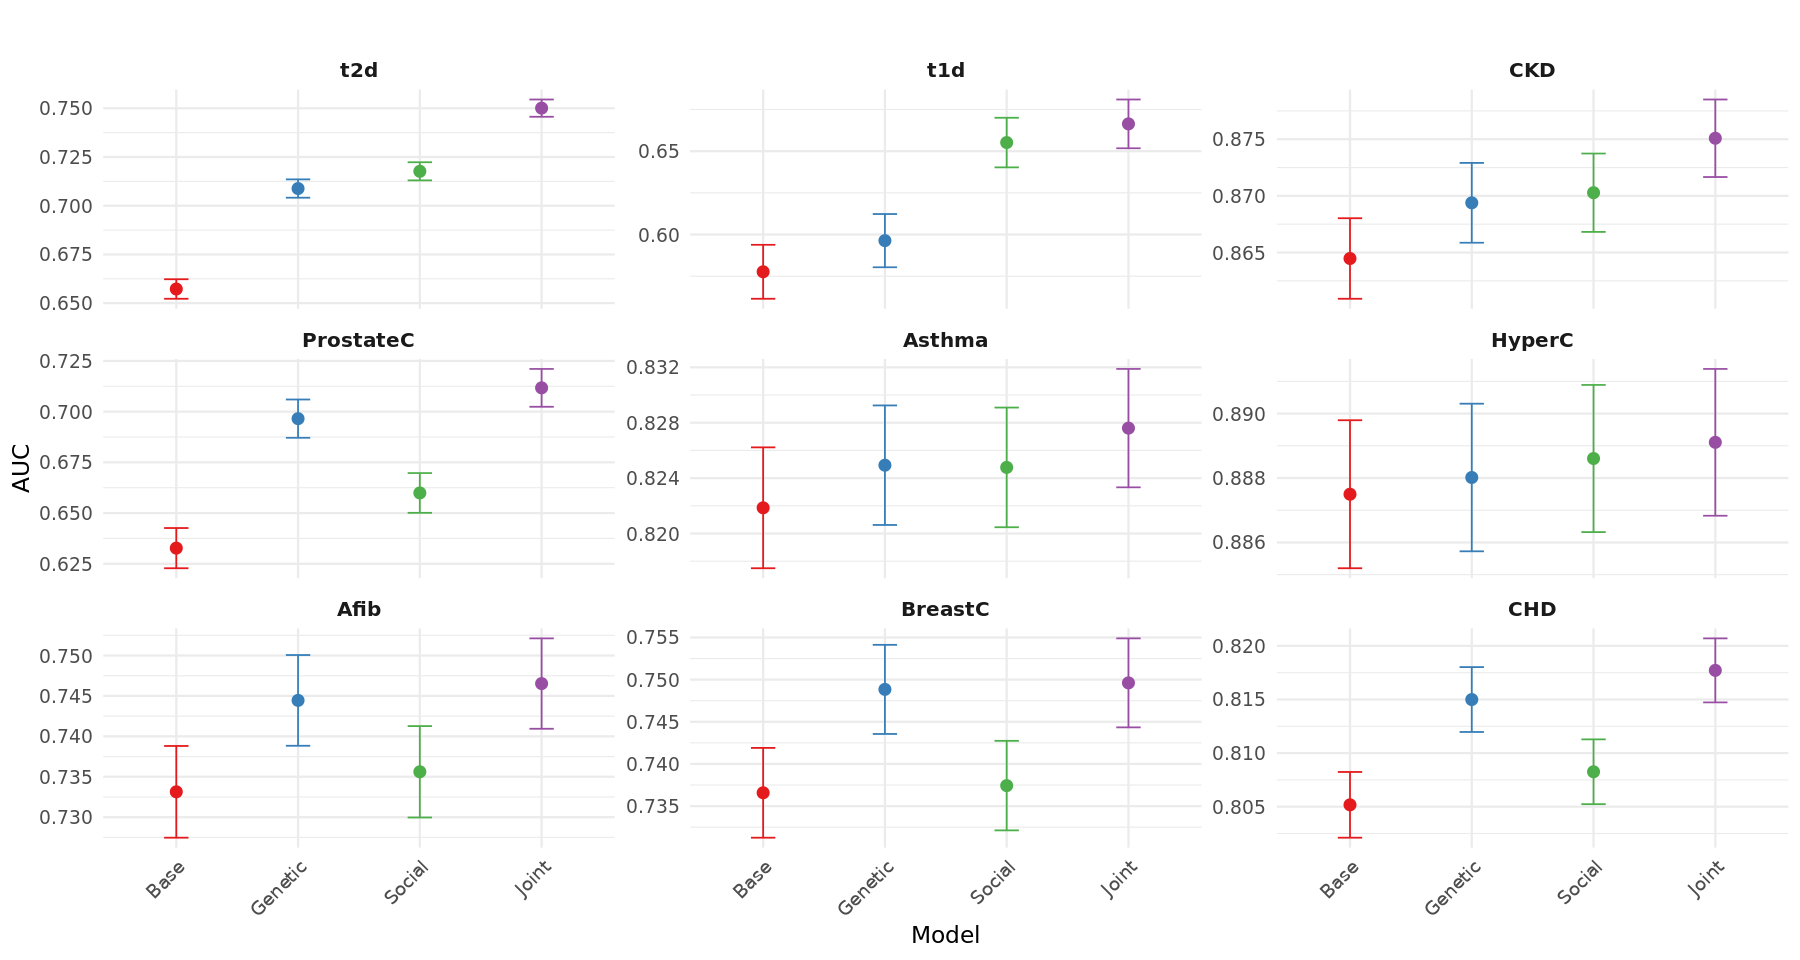

In [51]:


auc_plot_data$Disease <- factor(auc_plot_data$Disease, levels = 
                                c(
                                  "t2d", "t1d", "CKD", 
                                    "ProstateC", "Asthma", "HyperC",
                                  "Afib", "BreastC",  "CHD"
                            )) 


auc_plot_data$Model <- factor(auc_plot_data$Model, levels = 
                                c("Base", "Genetic", "Social",
                                    "Joint"))  

# Create the plot
auc_plot <- ggplot(auc_plot_data, aes(x = Model, y = AUC, color = Model)) +
  geom_point(position = position_dodge(width = 0.5), size = 3) +  # Points for AUC
  geom_errorbar(aes(ymin = AUC_CI_Lower, ymax = AUC_CI_Upper), 
                position = position_dodge(width = 0.5), width = 0.2) +  # Error bars for 95% CI
  facet_wrap(~ Disease, scales = "free_y", ncol = 3) +  # Adjust the number of columns to make the figure wider
  scale_color_brewer(palette = "Set1", name = "Model") +  # Color by Model
  labs(
    title = " ",
    x = "Model",
    y = "AUC"
  ) +
  theme_minimal(base_size = 14) +
  theme(
    axis.text.x = element_text(angle = 45, hjust = 1),
    strip.text = element_text(size = 12, face = "bold"),
    legend.title = element_text(face = "bold", hjust=.5)
  ) + theme(legend.position="none")

# Set plot size for Jupyter Notebook
options(repr.plot.width = 15, repr.plot.height = 8)  # Set width and height
print(auc_plot)

# Save the plot (optional)
ggsave("auc_plot_with_ci.png", plot = auc_plot, width = 15, height = 8, dpi = 300)


# Race / ethnicity stratified plots 

In [52]:
merged_data <- merged_data %>%
  mutate(
    SIRE = case_when(
      Black == 1 & His == 0 ~ "NH Black",
      White == 1 & His == 0 ~ "NH White",
      His == 1 ~ "HS",
      TRUE ~ "Underrepresented"
    )
  )

SIRES<-c("NH Black", "NH White", "HS", "Underrepresented")



In [59]:
# Updated function to fit models and extract results
fit_and_extract <- function(SIR, formulas, disease, domain, models, data) {
  map2_dfr(formulas, models, ~ {
      
    # Filter data based on disease-specific sex/gender logic
    filtered_data <- data |> filter(SIRE == SIR)
    
    if (disease %in% c("CKD", "t1d")) {
      filtered_data <- filtered_data %>% filter(SexGenderSGM == 0)
    }
    if (disease == "BreastC") {
      filtered_data <- filtered_data %>% filter(SexGenderCis_male == 0)
    }
    if (disease == "ProstateC") {
      filtered_data <- filtered_data %>% filter(SexGenderCis_female == 0)
    }

    # Remove rows with missing values in any variables used in the formula
    vars_in_model <- all.vars(.x)
    filtered_data <- filtered_data %>% filter(if_all(all_of(vars_in_model), ~ !is.na(.)))

    # Fit the model
    model <- glm(.x, data = filtered_data, family = binomial(link = "logit"))
    
    # Calculate predictions and actual values for AUC
    preds <- predict(model, type = "response")
    actuals <- model$y
    
    # Calculate AUC and 95% CI
    if (length(unique(actuals)) > 1) {
      roc_obj <- roc(actuals, preds, quiet = TRUE)  # ROC object
      auc <- as.numeric(roc_obj$auc)  # AUC value
      auc_ci <- ci.auc(roc_obj)  # AUC confidence interval
    } else {
      auc <- NA
      auc_ci <- c(NA, NA, NA)  # Placeholder for CI
    }
    
    # Model coefficients
    tidy(model) %>%
      mutate(
        SIRE = SIR,
        Disease = disease,
        Domain = domain,
        Model = .y,
        AUC = auc,
        AUC_CI_Lower = auc_ci[1],
        AUC_CI_Upper = auc_ci[3]
      )
  })
}

# Step 1: Generate combinations of diseases and domains
combinations <- expand_grid(
  disease = unlist(diseases),
  domain = domains, 
  SIR = SIRES
)

# Step 2: Generate formulas and fit models
results <- combinations %>%
  rowwise() %>%
  mutate(
    formulas = list(generate_formulas(disease, domain)),
    model_results = list(fit_and_extract(SIR, formulas, disease, domain, models, merged_data))
  ) %>%
  ungroup() %>%
  select(model_results) %>%
  unnest(model_results)

# Step 3: Clean and arrange results
results <- results %>%
  select(SIRE, Disease, Domain, Model, term, estimate, std.error, statistic, p.value, AUC, AUC_CI_Lower, AUC_CI_Upper)

# Print results
head(results)

Warning message:
“There were 112 warnings in `mutate()`.
The first warning was:
ℹ In argument: `model_results = list(...)`.
ℹ In row 2.
Caused by warning:
! glm.fit: fitted probabilities numerically 0 or 1 occurred
ℹ Run `dplyr::last_dplyr_warnings()` to see the 111 remaining warnings.”


SIRE,Disease,Domain,Model,term,estimate,std.error,statistic,p.value,AUC,AUC_CI_Lower,AUC_CI_Upper
<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
NH Black,Asthma,assisted_income,Base,(Intercept),-0.39089836,0.0928314922,-4.210838,2.544253e-05,0.8182419,0.8085377,0.827946
NH Black,Asthma,assisted_income,Base,age,-0.01792822,0.0018516897,-9.682087,3.593047e-22,0.8182419,0.8085377,0.827946
NH Black,Asthma,assisted_income,Base,record_depth,0.01404213,0.0005935266,23.658807,9.579987e-124,0.8182419,0.8085377,0.827946
NH Black,Asthma,assisted_income,Base,visit_frequency,-6.64038329,2.2290724668,-2.978989,2.892008e-03,0.8182419,0.8085377,0.827946
NH Black,Asthma,assisted_income,Base,SexGenderCis_male,-0.83975663,0.0622494069,-13.490195,1.786279e-41,0.8182419,0.8085377,0.827946
NH Black,Asthma,assisted_income,Base,SexGenderSGM,-0.39508144,0.1620854227,-2.437489,1.478966e-02,0.8182419,0.8085377,0.827946


In [62]:
# Step 2: Join domain lookup and restrict all models to the mapped domain
auc_plot_data <- results %>%
  filter(Model %in% c("Base", "Genetic", "Social", "Joint")) %>%
  filter(!is.na(AUC)) %>%
  left_join(social_domain_lookup, by = "Disease") %>%
  filter(Domain == Social_Domain) %>%  # Keep only rows where Domain matches mapped domain
  select(SIRE, Disease, Domain, Model, AUC, AUC_CI_Lower, AUC_CI_Upper) %>%
  distinct()

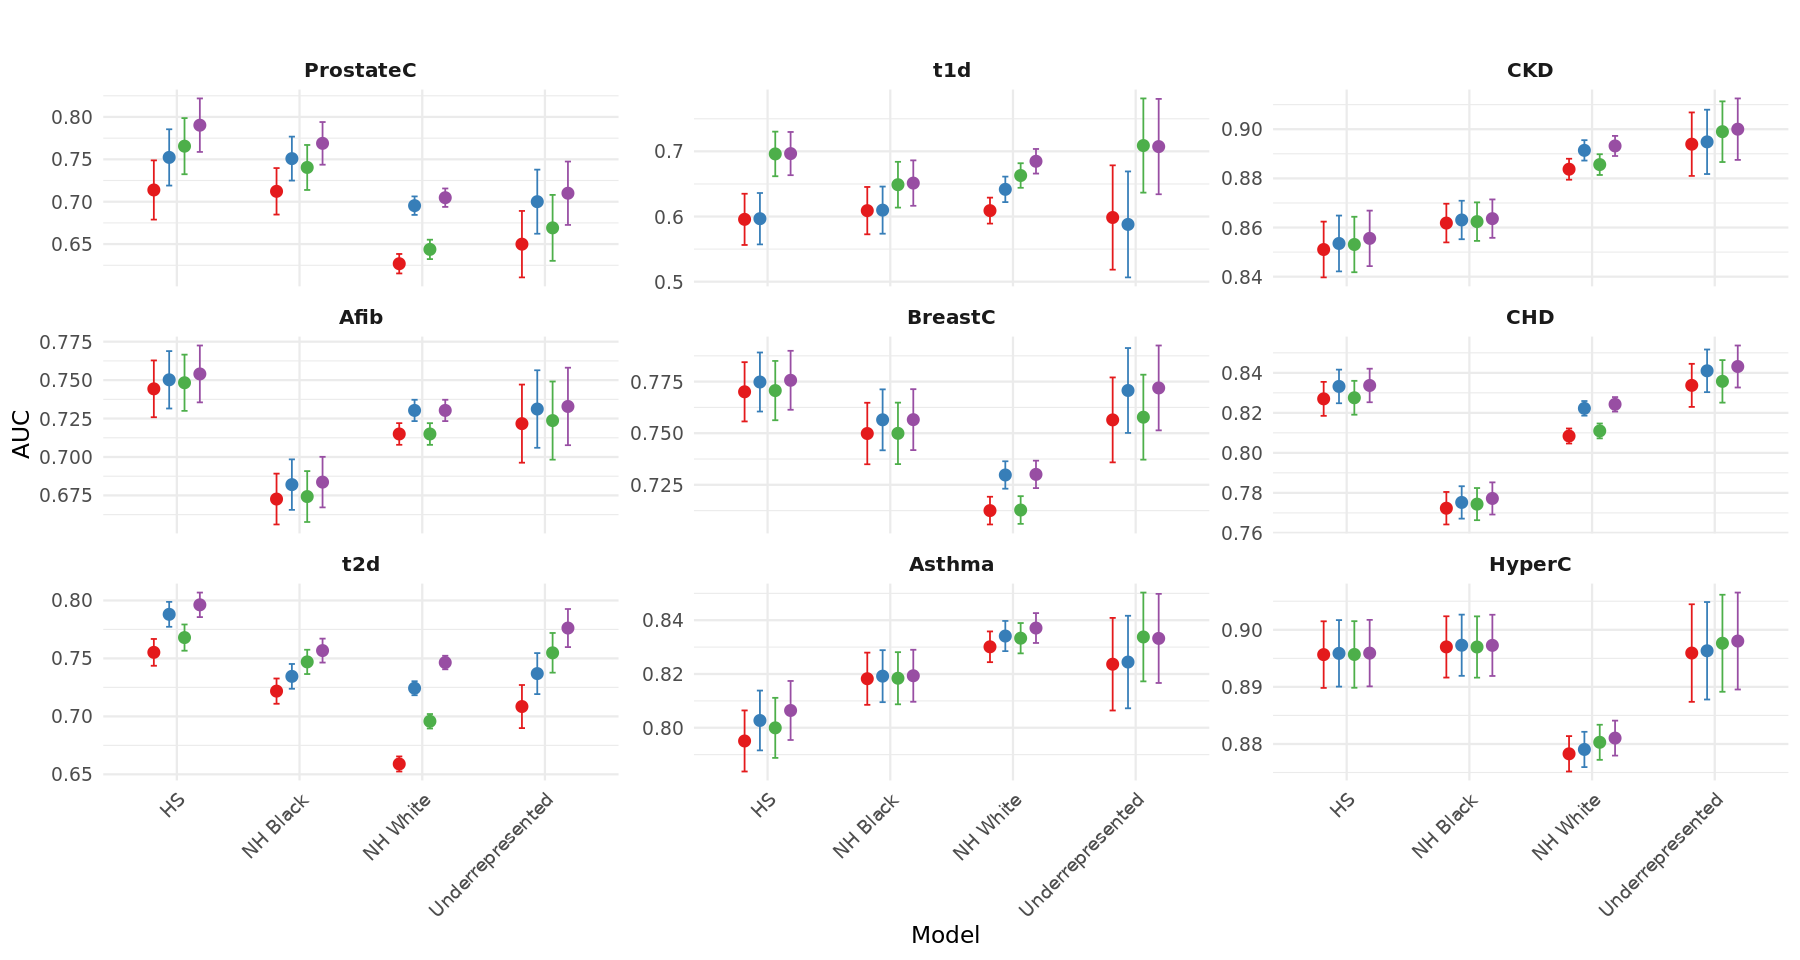

In [64]:
auc_plot_data$Disease <- factor(auc_plot_data$Disease, levels = 
                                c(
                                  "ProstateC", "t1d", "CKD", 
                                  "Afib", "BreastC",  "CHD",
                                 "t2d", "Asthma", "HyperC")) 


auc_plot_data$Model <- factor(auc_plot_data$Model, levels = 
                                c("Base", "Genetic", "Social", "Joint"))  

# Create the plot
auc_plot <- ggplot(auc_plot_data, aes(x = SIRE, y = AUC, color = Model)) +
  geom_point(position = position_dodge(width = 0.5), size = 3) +  # Points for AUC
  geom_errorbar(aes(ymin = AUC_CI_Lower, ymax = AUC_CI_Upper), 
                position = position_dodge(width = 0.5), width = 0.2) +  # Error bars for 95% CI
  facet_wrap(~ Disease, scales = "free_y", ncol = 3) +  # Adjust the number of columns to make the figure wider
  scale_color_brewer(palette = "Set1", name = "Model") +  # Color by Model
  labs(
    title = " ",
    x = "Model",
    y = "AUC"
  ) +
  theme_minimal(base_size = 14) +
  theme(
    axis.text.x = element_text(angle = 45, hjust = 1),
    strip.text = element_text(size = 12, face = "bold"),
    legend.title = element_text(face = "bold", hjust=.5)
  ) + theme(legend.position="none")

# Set plot size for Jupyter Notebook
options(repr.plot.width = 15, repr.plot.height = 8)  # Set width and height
print(auc_plot)

# Save the plot (optional)
ggsave("auc_plot_with_ci.png", plot = auc_plot, width = 15, height = 8, dpi = 300)